# AQUIRE under gate-level noise: estimates against the exact value

This notebook makes the estimate-vs-truth figure of the AQUIRE accuracy study. It runs AQUIRE
([arXiv:2605.00682](https://arxiv.org/abs/2605.00682)) on the paper's own test system, the periodic
qutrit plaquette, under several gate-level noise models of increasing strength. It then plots each
estimate and its noise-aware error bar against the exact value.

How it works:

* AQUIRE runs as in the paper: H⁴ diagnostics, one diagnostic shot per measurement shot, and the
  systematic error of Eq. 8b.
* The noise is simulated outside AQUIRE. `noise_models.GateNoiseSimulator` computes the exact noisy
  outcome probabilities of every measurement and diagnostic circuit. AQUIRE draws its shots from
  those probabilities through the `outcome_distribution_function` setting.
* Each noise model is a short file in `noise_models/`. All of them have the same error rate per
  gate, set relative to the paper's fitted rates (0.41% per single-qudit gate, 7.9% per entangling
  gate), so they differ only in the *type* of error.

**Run time.** Each run takes about a minute. The full figure is 5 models × 4 strengths × 2
commutation modes × 8 repeats = 320 runs: about 3 hours on 2 cores, or under 1 hour on 8.
Finished runs are saved in `results.jsonl` and skipped when the notebook is run again. Set
`QUICK = True` for a 5-minute version (one strength, one repeat, fewer shots).

In [1]:
import os
import sys

# Work from this notebook's folder, also when the kernel starts at the repository root (VS Code in
# SympleQ does). The folder goes on sys.path so that the parallel workers can import experiment.
if os.path.isdir("scripts/examples/notebooks/aquire_noise_models"):
    os.chdir("scripts/examples/notebooks/aquire_noise_models")
sys.path.insert(0, os.getcwd())

import experiment                      # before numba is imported: sets NUMBA_NUM_THREADS=1
import numpy as np
import matplotlib.pyplot as plt

from noise_models import MODELS, matched_infidelity, process_infidelity
from plaquette import plaquette_hamiltonian, product_state

QUICK = False                                     # True: a quick check of the whole pipeline
STRENGTHS = [1.0] if QUICK else [0.125, 0.25, 0.5, 1.0]   # x the paper's fitted error rates
REPEATS = 1 if QUICK else 8                       # runs per (model, strength, commutation mode)
SHOTS = (100, 1000) if QUICK else (100, 1000, 10000)      # AQUIRE's update steps; the figure uses the last
WORKERS = min(8, os.cpu_count() or 1)
RESULTS = "results_quick.jsonl" if QUICK else "results.jsonl"

## The system

The periodic plaquette of a 2D U(1) lattice gauge theory on three qutrits, at $g^2 = 0.01$. It has 86
Pauli strings besides the identity, as in the paper. The state is the hardware state of the paper,
$(|0\rangle+|1\rangle+|2\rangle)^{\otimes 3}/\sqrt{27}$. The identity string is not measured, so the
exact value below is that of the 86 measured strings.

In [2]:
H, psi = plaquette_hamiltonian(d=3, g2=0.01), product_state(d=3)
M = H.to_hilbert_space()
M = M.toarray() if hasattr(M, "toarray") else np.asarray(M)
print(f"{H.n_paulis()} Pauli strings, exact <O> = {np.real(psi.conj() @ M @ psi):.3f}")

86 Pauli strings, exact <O> = -229.630


## The noise models

| model | what happens after every gate (on the gate's qudits) | seen by AQUIRE's diagnostics? |
|---|---|---|
| `uniform` | AQUIRE's own model (Eq. F1): the whole outcome is random with probability ξ(C) | yes |
| `depolarising` | the qudits are replaced by the maximally mixed state with probability p | yes |
| `over_rotation` | a fixed rotation exp(−iθ(X+X†)/2) of each qudit | yes |
| `dephasing` | the qudits' coherences are destroyed with probability p | **no**: computational states are unchanged |
| `phase_error` | a fixed phase rotation exp(−iθ diag(k−1)) of each qudit | **no**: only phases change |

At strength *s*, every per-gate model has the process infidelity of local depolarising noise with
probability *s* × the paper's fitted rate. The paper's quoted hardware fidelity of 98.5% per
entangling gate corresponds to *s* ≈ 0.19. The check below computes each model's infidelity per
gate numerically and compares it with the target.

In [3]:
for name, Model in MODELS.items():
    model = Model(strength=1.0)
    print(model.describe())
    if name != "uniform":                         # the uniform model acts on whole circuits, not per gate
        print("   infidelity per gate (local, entangling):",
              [f"{process_infidelity(model, 3, k):.5f}" for k in ("local", "entangling")],
              " target:", [f"{matched_infidelity(1.0, 3, k):.5f}" for k in ("local", "entangling")])

uniform: p_local=0.00410, p_entangling=0.0790
depolarising: p_local=0.00410, p_entangling=0.0790
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']
over_rotation: theta_local=0.0854, theta_entangling=0.284
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']
dephasing: p_local=0.00547, p_entangling=0.0878
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']
phase_error: theta_local=0.0740, theta_entangling=0.246
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']


## Run AQUIRE

`experiment.run_one(model, strength, mode, repeat, shots)` is a single run. `experiment.run_grid`
runs every combination in parallel and appends each finished run to `RESULTS`. Seeds depend only on
the commutation mode and the repeat, so all models and strengths are compared on the same random
allocation.

In [4]:
runs = experiment.run_grid(list(MODELS), STRENGTHS, REPEATS, shots=SHOTS, path=RESULTS, workers=WORKERS)
print(f"{len(runs)} runs; mean run time {np.mean([r['seconds'] for r in runs]):.0f} s")

320 runs to do, 0 already saved in results.jsonl
  16/320 done (314 s)
  32/320 done (563 s)
  48/320 done (787 s)
  64/320 done (979 s)
  80/320 done (1245 s)
  96/320 done (1412 s)
  112/320 done (1669 s)
  128/320 done (1881 s)
  144/320 done (2139 s)
  160/320 done (2370 s)
  176/320 done (2569 s)
  192/320 done (2804 s)
  208/320 done (3017 s)
  224/320 done (3259 s)
  240/320 done (3502 s)
  256/320 done (3698 s)
  272/320 done (3932 s)
  288/320 done (4160 s)
  304/320 done (4389 s)
  320/320 done (4579 s)
320 runs; mean run time 114 s


## The figure

For each model (columns) and noise strength (horizontal axis), at the largest number of shots:

* **Faint dots:** single runs, as estimate − exact value, in % of |⟨O⟩|.
* **Marker with bar:** their mean, with AQUIRE's mean noise-aware error bar (1σ) around it.
* **Black line:** the exact value.

Where the bar does not reach the line, the estimate is outside its own error bar on average.

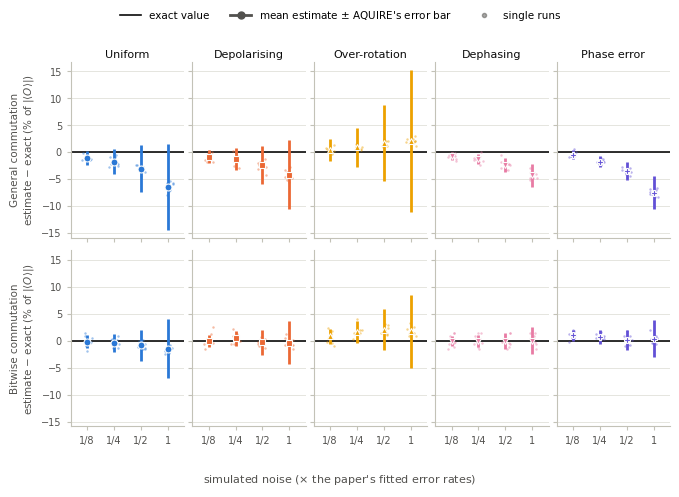

In [5]:
COLOUR = {"uniform": "#2a78d6", "depolarising": "#eb6834", "over_rotation": "#eda100",
          "dephasing": "#e87ba4", "phase_error": "#6250d6"}
MARKER = {"uniform": "o", "depolarising": "s", "over_rotation": "^", "dephasing": "v",
          "phase_error": "P"}
LABEL = {"uniform": "Uniform", "depolarising": "Depolarising", "over_rotation": "Over-rotation",
         "dephasing": "Dephasing", "phase_error": "Phase error"}
INK, INK2, GRID, BASE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"


def fraction(s):
    return f"1/{round(1 / s)}" if s < 1 else f"{s:g}"


def plot_estimates_vs_truth(runs, models, strengths, filename="aquire_estimates_vs_truth"):
    final = max(max(r["shots"]) for r in runs)
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(2, len(models), figsize=(1.2 * len(models) + 0.9, 5.0), sharex=True, sharey=True,
                             squeeze=False)
    for row, mode in enumerate(("general", "quditwise")):
        for col, model in enumerate(models):
            ax = axes[row, col]
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            for side in ("left", "bottom"):
                ax.spines[side].set_color(BASE)
            ax.tick_params(colors=INK2, labelsize=7, length=3, color=BASE)
            ax.grid(True, axis="y", color=GRID, lw=0.6, zorder=0)
            ax.axhline(0, color=INK, lw=1.2, zorder=2)
            for x, s in enumerate(strengths):
                sel = [r for r in runs if r["model"] == model and r["mode"] == mode and r["strength"] == s
                       and max(r["shots"]) == final]
                if not sel:
                    continue
                k = sel[0]["shots"].index(final)
                rel = np.array([100 * (r["estimate"][k] / r["exact"] - 1) for r in sel])
                bar = np.mean([100 * r["error_bar"][k] / abs(r["exact"]) for r in sel])
                ax.plot(x + rng.uniform(-0.18, 0.18, len(rel)), rel, ".", ms=3.5, color=COLOUR[model], alpha=0.45,
                        mec="none", zorder=3)
                ax.errorbar([x], [rel.mean()], yerr=[bar], fmt=MARKER[model], ms=5, color=COLOUR[model],
                            mec="#fcfcfb", mew=0.8, elinewidth=2, capsize=0, zorder=4)
            if row == 0:
                ax.set_title(LABEL[model], fontsize=8, color=INK, pad=3)
            ax.set_xticks(range(len(strengths)))
            ax.set_xticklabels([fraction(s) for s in strengths], fontsize=7)
            ax.set_xlim(-0.6, len(strengths) - 0.4)
        axes[row, 0].set_ylabel(("General" if mode == "general" else "Bitwise") + " commutation\n"
                                "estimate $-$ exact (% of $|\\langle O\\rangle|$)", fontsize=7.5, color=INK2)
    fig.supxlabel("simulated noise ($\\times$ the paper's fitted error rates)", fontsize=8, color=INK2, y=0.035)
    handles = [plt.Line2D([], [], color=INK, lw=1.2, label="exact value"),
               plt.Line2D([], [], color=INK2, marker="o", ms=5, lw=2, label="mean estimate $\\pm$ AQUIRE's error bar"),
               plt.Line2D([], [], color=INK2, marker=".", ms=6, lw=0, alpha=0.5, label="single runs")]
    fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=7.5)
    fig.tight_layout(rect=(0, 0.03, 1, 0.94), h_pad=0.6, w_pad=0.3)
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}", dpi=200)
    return fig


plot_estimates_vs_truth(runs, list(MODELS), STRENGTHS)
plt.show()

## Reading the figure

* Under noise that AQUIRE's diagnostics detect (uniform, depolarising, over-rotation), the
  error bar grows with the noise and reaches the exact value.
* Under dephasing and phase errors with general commutation, the estimate drifts away just as much,
  but the diagnostics, which start from |0…0⟩, see almost no error. The error bar stays at its
  statistical size and misses the exact value.
* With bitwise commutation the measurement circuits contain only single-qudit gates, so the
  estimates stay close to the exact value at every strength.